In [1]:
import scanpy as sc
adata_fibroblast = sc.read("../h5ad/adata_fibroblast.h5ad")
sc.pp.normalize_total(adata_fibroblast, target_sum=1e6)
sc.pp.log1p(adata_fibroblast)

/tmp/ipykernel_2198948/1170093487.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


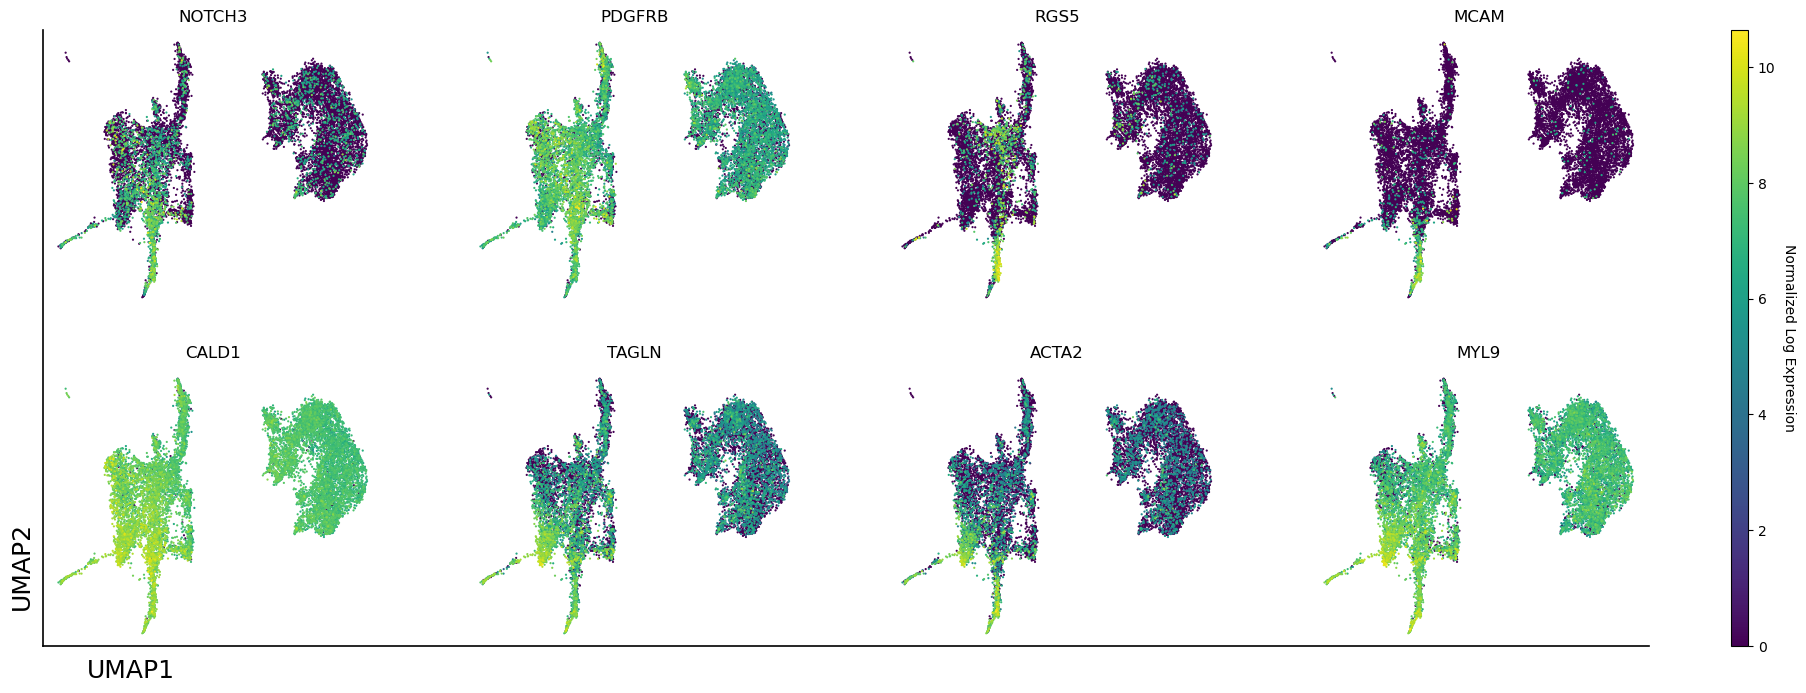

In [2]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.gridspec as gridspec

# 1. Define the gene list
marker_genes = ['NOTCH3', 'PDGFRB', 'RGS5', 'MCAM', 
                'CALD1', 'TAGLN', 'ACTA2', 'MYL9']

# 2. Set global font (prevent the '+' sign from turning into a box)
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans'],
    'axes.unicode_minus': False
})

# 3. Create canvas and GridSpec layout
# Key change: ncols=5, the first 4 columns for plots, the 5th column for the colorbar
fig = plt.figure(figsize=(22, 8))
gs = gridspec.GridSpec(2, 5, width_ratios=[1, 1, 1, 1, 0.05], wspace=0.3)

# 4. Loop through genes to plot
for idx, gene in enumerate(marker_genes):
    # Calculate the position of the current subplot in GridSpec (first two rows, first four columns)
    row = idx // 4
    col = idx % 4
    ax = fig.add_subplot(gs[row, col])
    
    # [Key] Use sc.pl.umap and specify ax
    sc.pl.umap(
        adata_fibroblast, 
        color=gene, 
        ax=ax, 
        show=False, 
        title=gene,       
        frameon=False,    
        legend_loc=None,  
        size=10,          
        colorbar_loc=None  # [Core change] Completely disable the built-in colorbar of the subplot
    )

# ==========================================
# 4.5 Add global UMAP1 / UMAP2 axes (fixed version)
# ==========================================
# Get the overall bounding box of the first 4 columns (where the 8 subplots are located)
bbox = gs[:, :4].get_position(fig)

# Add lines directly on the canvas instead of creating new subplots
# Bottom X-axis line
fig.add_artist(plt.Line2D(
    [bbox.x0, bbox.x1], [bbox.y0, bbox.y0], 
    transform=fig.transFigure, color='black', linewidth=1.2
))
# Left Y-axis line
fig.add_artist(plt.Line2D(
    [bbox.x0, bbox.x0], [bbox.y0, bbox.y1], 
    transform=fig.transFigure, color='black', linewidth=1.2
))

# Add text labels at corresponding positions
fig.text(bbox.x0 + 0.04, bbox.y0 - 0.04, 'UMAP1', fontsize=18, ha='center')
fig.text(bbox.x0-0.015, bbox.y0 + 0.10, 'UMAP2', fontsize=18, rotation=90, va='center')
# ==========================================
# ==========================================

# 5. Add a global unified colorbar
# Key change: the colorbar axis occupies the 5th column and spans both rows (rowspan=2)
cax = fig.add_subplot(gs[:, 4]) 

# Get the data range for generating the colorbar
vmax = max([adata_fibroblast[:, g].X.max() for g in marker_genes])

# Create a virtual mappable and draw the colorbar
sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=0, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label('Normalized Log Expression', rotation=270, labelpad=15)

# 6. Adjust layout and display
plt.tight_layout()
plt.show()